In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import os
!pip install xlsxwriter
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from datetime import datetime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 5.7 MB/s eta 0:00:00


In [ ]:
# =========================================
# 1) TICKERS
# =========================================
lq45_tickers = [
    "ACES.JK", "ADRO.JK", "AKRA.JK", "ANTM.JK", "ASII.JK", "BBCA.JK", "BBNI.JK",
    "BBRI.JK", "BBTN.JK", "BMRI.JK", "BRPT.JK", "BSDE.JK", "CPIN.JK", "ERAA.JK",
    "EXCL.JK", "GGRM.JK", "HMSP.JK", "ICBP.JK", "INCO.JK", "INDF.JK", "INKP.JK",
    "INTP.JK", "ITMG.JK", "JPFA.JK", "JSMR.JK", "KLBF.JK", "MDKA.JK", "MEDC.JK",
    "MIKA.JK", "MNCN.JK", "PGAS.JK", "PTBA.JK", "PTPP.JK", "PWON.JK", "SMGR.JK",
    "SMRA.JK", "TBIG.JK", "TINS.JK", "TKIM.JK", "TLKM.JK", "TOWR.JK", "TPIA.JK",
    "UNTR.JK", "UNVR.JK", "WIKA.JK"
]

djia_tickers = [
    "AAPL", "AMGN", "AXP", "BA", "CAT", "CRM", "CSCO", "CVX", "DIS", "GS",
    "HD", "HON", "IBM", "JNJ", "JPM", "KO", "MCD", "MMM", "MRK", "MSFT",
    "NKE", "PG", "SHW", "TRV", "UNH", "V", "VZ", "WMT", "AMZN", "NVDA"
]

sse50_tickers = [
    "600000.SS", "600016.SS", "600028.SS", "600030.SS", "600031.SS",
    "600036.SS", "600048.SS", "600050.SS", "600089.SS", "600104.SS",
    "600111.SS", "600150.SS", "600309.SS", "600406.SS", "600436.SS",
    "600438.SS", "600519.SS", "600690.SS", "600809.SS", "600887.SS",
    "600893.SS", "600900.SS", "600905.SS", "600941.SS", "601012.SS",
    "601066.SS", "601088.SS", "601138.SS", "601166.SS", "601211.SS",
    "601225.SS", "601288.SS", "601318.SS", "601390.SS", "601398.SS",
    "601601.SS", "601628.SS", "601668.SS", "601688.SS", "601728.SS",
    "601857.SS", "601888.SS", "601899.SS", "601919.SS", "601985.SS",
    "603288.SS", "603501.SS", "603799.SS", "688111.SS", "688599.SS"
]

indices_dict = {
    "LQ45": lq45_tickers,
    "DJIA": djia_tickers,
    "SSE50": sse50_tickers
}


In [ ]:
# =========================================
# 2) CONFIG
# =========================================
LOOKBACK = 20
HORIZON = 7

START_DATE = "2021-01-01"
END_DATE = "2026-02-28"

TRAIN_END = pd.Timestamp("2025-12-31")
TEST_START = pd.Timestamp("2026-01-01")
TEST_END = pd.Timestamp("2026-02-28")
FORECAST_START = pd.Timestamp("2026-03-01")

EPOCHS = 70
BATCH_SIZE = 16

OUTPUT_DIR = "lstm_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================
# RISK-FREE RATE — Indonesia ORI028T3
# ORI028T3 gross coupon: 5.35% per year
# Source: DJPPR Kemenkeu, published 29 Sep 2025
# Daily equivalent (trading-day basis): 5.35% / 252
# =========================================
ORI_ANNUAL = 0.0535          # 5.35% gross per year
RF_DAILY   = ORI_ANNUAL / 252  # ≈ 0.000212 per trading day

print(f'Risk-free rate (daily): {RF_DAILY:.6f}')
print(f'Risk-free rate (annual): {ORI_ANNUAL*100:.2f}%  [ORI028T3]')

Risk-free rate (daily): 0.000212
Risk-free rate (annual): 5.35%  [ORI028T3]


In [ ]:
# =========================================
# 3A) BUILD RAW MARKET DATA + EXPORT TO EXCEL
# =========================================
import os
import pandas as pd

RAW_DATA_DIR = "raw_market_data"
os.makedirs(RAW_DATA_DIR, exist_ok=True)

raw_data = {}

# Ensure get_clean_data is defined before this loop
# The definition of get_clean_data is in cell 6S5lC4S-pBRx and needs to be executed first.

for index_name, tickers in indices_dict.items():
    prices, returns = get_clean_data(tickers)

    raw_data[index_name] = {
        "clean_prices": prices,
        "log_returns": returns
    }

    file_path = os.path.join(RAW_DATA_DIR, f"{index_name.lower()}_raw_data.xlsx")

    with pd.ExcelWriter(file_path, engine="openpyxl") as writer:
        prices.to_excel(writer, sheet_name="clean_prices")
        returns.to_excel(writer, sheet_name="log_returns")

    print(f"Saved raw data: {file_path}")

NameError: name 'get_clean_data' is not defined

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# baca file excel
lq45 = pd.read_excel("raw_market_data/lq45_raw_data.xlsx", sheet_name="log_returns", index_col=0)
djia = pd.read_excel("raw_market_data/djia_raw_data.xlsx", sheet_name="log_returns", index_col=0)
sse50 = pd.read_excel("raw_market_data/sse50_raw_data.xlsx", sheet_name="log_returns", index_col=0)

# ubah index ke datetime kalau perlu
lq45.index = pd.to_datetime(lq45.index)
djia.index = pd.to_datetime(djia.index)
sse50.index = pd.to_datetime(sse50.index)

# average daily log return per market
lq45_avg = lq45.mean(axis=1).dropna()
djia_avg = djia.mean(axis=1).dropna()
sse50_avg = sse50.mean(axis=1).dropna()

plt.figure(figsize=(10, 6))
plt.hist(lq45_avg, bins=40, alpha=0.5, label="LQ45")
plt.hist(djia_avg, bins=40, alpha=0.5, label="DJIA")
plt.hist(sse50_avg, bins=40, alpha=0.5, label="SSE50")

plt.title("Histogram of Average Daily Log Returns")
plt.xlabel("Average Daily Log Return")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ==============================
# CONFIG
# ==============================
TRAIN_END = "2025-12-31"
TEST_START = "2026-01-01"
TEST_END = "2026-02-28"

# ==============================
# LOAD LOG RETURNS FROM EXCEL
# ==============================
lq45 = pd.read_excel("raw_market_data/lq45_raw_data.xlsx", sheet_name="log_returns", index_col=0)
djia = pd.read_excel("raw_market_data/djia_raw_data.xlsx", sheet_name="log_returns", index_col=0)
sse50 = pd.read_excel("raw_market_data/sse50_raw_data.xlsx", sheet_name="log_returns", index_col=0)

lq45.index = pd.to_datetime(lq45.index)
djia.index = pd.to_datetime(djia.index)
sse50.index = pd.to_datetime(sse50.index)

# average daily log return per market
lq45_avg = lq45.mean(axis=1).dropna()
djia_avg = djia.mean(axis=1).dropna()
sse50_avg = sse50.mean(axis=1).dropna()

# ==============================
# SPLIT TRAIN / TEST
# ==============================
lq45_train = lq45_avg[lq45_avg.index <= TRAIN_END]
djia_train = djia_avg[djia_avg.index <= TRAIN_END]
sse50_train = sse50_avg[sse50_avg.index <= TRAIN_END]

lq45_test = lq45_avg[(lq45_avg.index >= TEST_START) & (lq45_avg.index <= TEST_END)]
djia_test = djia_avg[(djia_avg.index >= TEST_START) & (djia_avg.index <= TEST_END)]
sse50_test = sse50_avg[(sse50_avg.index >= TEST_START) & (sse50_avg.index <= TEST_END)]

# ==============================
# HISTOGRAM - TRAINING PERIOD
# ==============================
plt.figure(figsize=(10, 6))
plt.hist(lq45_train, bins=40, alpha=0.5, label="LQ45")
plt.hist(djia_train, bins=40, alpha=0.5, label="DJIA")
plt.hist(sse50_train, bins=40, alpha=0.5, label="SSE50")

plt.title("Histogram of Average Daily Log Returns - Training Period")
plt.xlabel("Average Daily Log Return")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.show()

# ==============================
# HISTOGRAM - TESTING PERIOD
# ==============================
plt.figure(figsize=(10, 6))
plt.hist(lq45_test, bins=20, alpha=0.5, label="LQ45")
plt.hist(djia_test, bins=20, alpha=0.5, label="DJIA")
plt.hist(sse50_test, bins=20, alpha=0.5, label="SSE50")

plt.title("Histogram of Average Daily Log Returns - Testing Period")
plt.xlabel("Average Daily Log Return")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# =========================================
# 3) DATA DOWNLOAD + CLEANING
# =========================================
def get_clean_data(tickers, start_date=START_DATE, end_date=END_DATE):
    print(f"Downloading {len(tickers)} tickers...")

    raw = yf.download(
        tickers,
        start=start_date,
        end=end_date,
        auto_adjust=False,
        progress=False
    )

    if raw.empty:
        raise ValueError("Yahoo Finance returned empty data.")

    # Use only Close
    if isinstance(raw.columns, pd.MultiIndex):
        if "Close" not in raw.columns.get_level_values(0):
            raise ValueError("Close column not found in downloaded data.")
        prices = raw["Close"].copy()
    else:
        # single ticker fallback
        if "Close" not in raw.columns:
            raise ValueError("Close column not found in downloaded data.")
        prices = raw[["Close"]].copy()
        if len(tickers) == 1:
            prices.columns = [tickers[0]]

    prices = prices.sort_index()

    # Fill missing calendar days due to holidays using previous price
    prices = prices.ffill().dropna(how="all")

    # Log returns
    returns = np.log(prices / prices.shift(1)).dropna(how="all")

    return prices, returns


In [ ]:
# =========================================
# 4) SEQUENCE CREATION
# =========================================
def create_sequences_with_dates(series, dates, lookback=20):
    X, y, target_dates = [], [], []

    for i in range(len(series) - lookback):
        X.append(series[i:i + lookback])
        y.append(series[i + lookback])
        target_dates.append(dates[i + lookback])

    X = np.array(X)
    y = np.array(y)
    target_dates = pd.to_datetime(np.array(target_dates))

    return X, y, target_dates


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# =========================================
# 5) TRAIN LSTM BY DATE
# =========================================
def train_lstm_by_date(series, dates, lookback=20, epochs=EPOCHS, batch_size=16):
    series = np.asarray(series, dtype=np.float32).reshape(-1, 1)
    dates = np.array(dates)

    # -----------------------------
    # 1) Split raw series by date first
    # -----------------------------
    train_raw_mask = dates <= TRAIN_END
    test_raw_mask = (dates >= TEST_START) & (dates <= TEST_END)

    train_raw = series[train_raw_mask]
    test_raw = series[test_raw_mask]
    train_dates_raw = dates[train_raw_mask]
    test_dates_raw = dates[test_raw_mask]

    if len(train_raw) <= lookback:
        raise ValueError("Train raw series terlalu pendek untuk lookback.")
    if len(test_raw) == 0:
        raise ValueError("Test raw series kosong.")

    # -----------------------------
    # 2) Fit scaler ONLY on training data
    # -----------------------------
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaler.fit(train_raw)

    # Scale the entire series for forecasting purposes
    full_scaled_data = scaler.transform(series).flatten()

    train_scaled = scaler.transform(train_raw).flatten()
    test_scaled = scaler.transform(test_raw).flatten()

    # -----------------------------
    # 3) Build train sequences
    # -----------------------------
    X_train_full, y_train_full, train_target_dates = create_sequences_with_dates(
        train_scaled,
        train_dates_raw,
        lookback=lookback
    )

    if len(X_train_full) == 0:
        raise ValueError("Train sequence kosong setelah create_sequences_with_dates.")

    # -----------------------------
    # 4) Build test sequences
    #    Need last lookback points from train to seed test window
    # -----------------------------
    combined_for_test = np.concatenate([train_scaled[-lookback:], test_scaled])
    combined_test_dates = np.concatenate([train_dates_raw[-lookback:], test_dates_raw])

    X_test, y_test, test_target_dates = create_sequences_with_dates(
        combined_for_test,
        combined_test_dates,
        lookback=lookback
    )

    # only keep real test targets
    test_seq_mask = (test_target_dates >= TEST_START) & (test_target_dates <= TEST_END)
    X_test = X_test[test_seq_mask]
    y_test = y_test[test_seq_mask]
    test_dates = test_target_dates[test_seq_mask]

    if len(X_test) == 0:
        raise ValueError("Test sequence kosong setelah create_sequences_with_dates.")

    # -----------------------------
    # 5) Chronological validation split from training sequences
    #    Last 10% of training sequences = validation
    # -----------------------------
    val_size = max(1, int(len(X_train_full) * 0.1))

    if len(X_train_full) <= val_size:
        raise ValueError("Train sequence terlalu sedikit untuk validation split.")

    X_train = X_train_full[:-val_size]
    y_train = y_train_full[:-val_size]

    X_val = X_train_full[-val_size:]
    y_val = y_train_full[-val_size:]

    if len(X_train) == 0 or len(X_val) == 0:
        raise ValueError("Split train/validation gagal.")

    # reshape for LSTM
    X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
    X_val = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))
    X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

    # -----------------------------
    # 6) Build model
    # -----------------------------
    model = Sequential([
        LSTM(50, return_sequences=True, input_shape=(lookback, 1)),
        Dropout(0.2),
        LSTM(50, return_sequences=False),
        Dropout(0.2),
        Dense(1)
    ])

    model.compile(optimizer="adam", loss="mse", metrics=["mae"])

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        min_delta=1e-5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        verbose=0,
        shuffle=False,
        callbacks=[early_stop]
    )

    return {
        "model": model,
        "scaler": scaler,
        "train_scaled": train_scaled,
        "test_scaled": test_scaled,
        "X_test": X_test,
        "y_test": y_test,
        "test_dates": test_dates,
        "history": history,
        "epochs_ran": len(history.history["loss"]),
        "best_val_loss": np.min(history.history["val_loss"]),
        "scaled_series": full_scaled_data # Add the full scaled series
    }

In [ ]:
# =========================================
# 6) EVALUATION
# =========================================
def evaluate_lstm_test(model_obj):
    pred_scaled = model_obj["model"].predict(model_obj["X_test"], verbose=0).flatten()

    pred = model_obj["scaler"].inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
    actual = model_obj["scaler"].inverse_transform(model_obj["y_test"].reshape(-1, 1)).flatten()

    rmse = np.sqrt(np.mean((actual - pred) ** 2))
    mae = np.mean(np.abs(actual - pred))

    pred_df = pd.DataFrame({
        "Date": pd.to_datetime(model_obj["test_dates"]),
        "Actual": actual,
        "Predicted": pred
    })

    return {
        "RMSE": rmse,
        "MAE": mae,
        "predictions": pred_df
    }

In [ ]:
# =========================================
# 7) FUTURE FORECAST
# =========================================
def forecast_future_lstm(model_obj, lookback=20, horizon=7):
    model = model_obj["model"]
    scaler = model_obj["scaler"]
    scaled_series = model_obj["scaled_series"]

    current_window = scaled_series[-lookback:].reshape(1, lookback, 1)
    future_scaled = []

    for _ in range(horizon):
        pred = model.predict(current_window, verbose=0)[0, 0]
        future_scaled.append(pred)

        new_entry = np.array([[[pred]]], dtype=np.float32)
        current_window = np.append(current_window[:, 1:, :], new_entry, axis=1)

    future_values = scaler.inverse_transform(
        np.array(future_scaled).reshape(-1, 1)
    ).flatten()

    future_dates = pd.date_range(start=FORECAST_START, periods=horizon, freq="D")

    return pd.DataFrame({
        "Date": future_dates,
        "Predicted": future_values
    })

In [ ]:
# =========================================
# 8) RETURN TO PRICE
# =========================================
def returns_to_prices(last_price, log_returns):
    return last_price * np.exp(np.cumsum(log_returns))

In [ ]:
# =========================================
# 9) PROCESS ONE INDEX
# =========================================
def process_index(index_name, tickers, lookback=20, horizon=7, epochs=EPOCHS, batch_size=16):
    print(f"\n========== PROCESSING {index_name} ==========")

    prices_df, returns_df = get_clean_data(tickers)

    evaluation_rows = []
    test_prediction_rows = []
    future_return_rows = []
    future_price_rows = []
    failed_tickers = []

    available_tickers = [
        tk for tk in tickers
        if tk in returns_df.columns and tk in prices_df.columns
    ]

    for ticker in available_tickers:
        print(f"Processing {ticker}...")

        try:
            series_ret = returns_df[ticker].dropna()
            dates_ret = series_ret.index

            if len(series_ret) <= lookback + 30:
                print(f"  Skip {ticker}: data terlalu pendek")
                failed_tickers.append(ticker)
                continue

            ret_model = train_lstm_by_date(
                series=series_ret.values,
                dates=dates_ret,
                lookback=lookback,
                epochs=epochs,
                batch_size=batch_size
            )

            ret_eval = evaluate_lstm_test(ret_model)
            future_ret = forecast_future_lstm(
                ret_model,
                lookback=lookback,
                horizon=horizon
            )

            future_ret = future_ret.rename(columns={"Predicted": "Predicted_Log_Return"})
            future_ret["Ticker"] = ticker
            future_ret["Index"] = index_name

            last_price = prices_df[ticker].dropna().iloc[-1]
            future_prices = returns_to_prices(
                last_price,
                future_ret["Predicted_Log_Return"].values
            )

            future_price_df = future_ret[["Date", "Ticker", "Index"]].copy()
            future_price_df["Predicted_Close"] = future_prices

            test_pred_df = ret_eval["predictions"].copy()
            test_pred_df["Ticker"] = ticker
            test_pred_df["Index"] = index_name

            evaluation_rows.append({
                "Ticker": ticker,
                "Index": index_name,
                "Return_RMSE": ret_eval["RMSE"],
                "Return_MAE": ret_eval["MAE"]
            })

            test_prediction_rows.append(test_pred_df)
            future_return_rows.append(future_ret)
            future_price_rows.append(future_price_df)

            print(f"  Done: {ticker}")

        except Exception as e:
            print(f"  Failed: {ticker} | Error: {e}")
            failed_tickers.append(ticker)

    evaluation_df = pd.DataFrame(evaluation_rows)
    test_predictions_df = (
        pd.concat(test_prediction_rows, ignore_index=True)
        if test_prediction_rows else pd.DataFrame()
    )
    future_returns_df = (
        pd.concat(future_return_rows, ignore_index=True)
        if future_return_rows else pd.DataFrame()
    )
    future_prices_df = (
        pd.concat(future_price_rows, ignore_index=True)
        if future_price_rows else pd.DataFrame()
    )
    failed_df = pd.DataFrame({
        "Ticker": failed_tickers,
        "Index": index_name
    })

    output_path = os.path.join(OUTPUT_DIR, f"hasil_lstm_{index_name.lower()}.xlsx")

    with pd.ExcelWriter(output_path, engine="xlsxwriter") as writer:
        prices_df.to_excel(writer, sheet_name="clean_prices")
        returns_df.to_excel(writer, sheet_name="log_returns")
        evaluation_df.to_excel(writer, sheet_name="evaluation", index=False)
        test_predictions_df.to_excel(writer, sheet_name="test_predictions", index=False)
        future_returns_df.to_excel(writer, sheet_name="future_returns", index=False)
        future_prices_df.to_excel(writer, sheet_name="future_prices", index=False)
        failed_df.to_excel(writer, sheet_name="failed_tickers", index=False)

    print(f"Saved: {output_path}")

    return {
        "clean_prices": prices_df,
        "log_returns": returns_df,
        "evaluation": evaluation_df,
        "test_predictions": test_predictions_df,
        "future_returns": future_returns_df,
        "future_prices": future_prices_df,
        "failed_tickers": failed_df
    }

In [ ]:
# =========================================
# 10) RUN ALL INDICES
# =========================================
all_results = {}

for idx_name, tickers in indices_dict.items():
    result = process_index(
        index_name=idx_name,
        tickers=tickers,
        lookback=LOOKBACK,
        horizon=HORIZON,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE
    )
    all_results[idx_name] = result

print("\nSemua indeks selesai diproses.")


========== PROCESSING LQ45 ==========
Processing ACES.JK...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


  Done: ACES.JK
Processing ADRO.JK...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


  Done: ADRO.JK
Processing AKRA.JK...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


... (241 outputs left out)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


  Done: 688111.SS
Processing 688599.SS...


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


  Done: 688599.SS
Saved: lstm_outputs/hasil_lstm_sse50.xlsx

Semua indeks selesai diproses.


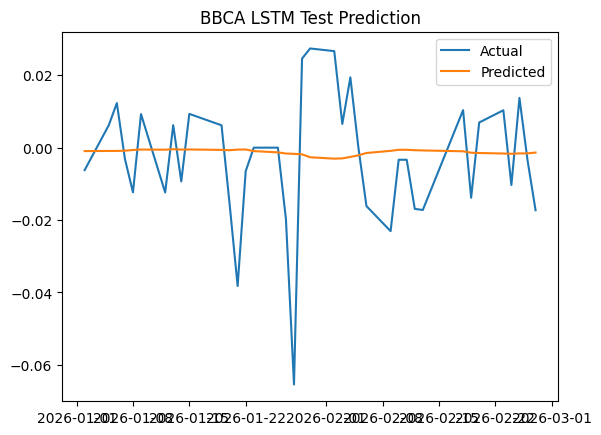

In [ ]:
import matplotlib.pyplot as plt

df = all_results["LQ45"]["test_predictions"]

sample = df[df["Ticker"] == "BBCA.JK"]

plt.plot(sample["Date"], sample["Actual"], label="Actual")
plt.plot(sample["Date"], sample["Predicted"], label="Predicted")
plt.legend()
plt.title("BBCA LSTM Test Prediction")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import os

RISK_OUTPUT_DIR = "risk_outputs"
os.makedirs(RISK_OUTPUT_DIR, exist_ok=True)

def var_95(x):
    x = pd.Series(x).dropna()
    if len(x) == 0:
        return np.nan
    return np.quantile(x, 0.05)

def cvar_95(x):
    x = pd.Series(x).dropna()
    if len(x) == 0:
        return np.nan
    v = np.quantile(x, 0.05)
    tail = x[x <= v]
    if len(tail) == 0:
        return np.nan
    return tail.mean()

def mad(x):
    x = pd.Series(x).dropna()
    if len(x) == 0:
        return np.nan
    mu = x.mean()
    return np.mean(np.abs(x - mu))

def summarize_risk_return(returns_df):
    rows = []

    for ticker in returns_df.columns:
        x = returns_df[ticker].dropna()

        if len(x) == 0:
            continue

        mean_ret = x.mean()
        sd_ret = x.std(ddof=1)
        var95 = var_95(x)
        cvar95 = cvar_95(x)
        mad_val = mad(x)

        rows.append({
            "Ticker": ticker,
            "N_Obs": len(x),
            "Mean_Return_Historical": mean_ret,
            "Risk_SD": sd_ret,
            "VaR_95": var95,
            "CVaR_95": cvar95,
            "MAD": mad_val,
            "Abs_VaR": abs(var95) if pd.notna(var95) else np.nan,
            "Abs_CVaR": abs(cvar95) if pd.notna(cvar95) else np.nan
        })

    summary_df = pd.DataFrame(rows)
    summary_df = summary_df.sort_values(["Risk_SD", "Mean_Return_Historical"], ascending=[True, False])
    return summary_df

def build_expected_return_from_lstm(future_returns_df):
    """
    Mengubah hasil forecast return harian 7 hari menjadi expected return per ticker.
    Di sini dipakai rata-rata predicted log return sebagai expected return harian.
    """
    if future_returns_df.empty:
        return pd.DataFrame(columns=["Ticker", "Expected_Return_LSTM"])

    out = (
        future_returns_df
        .groupby("Ticker", as_index=False)["Predicted_Log_Return"]
        .mean()
        .rename(columns={"Predicted_Log_Return": "Expected_Return_LSTM"})
    )
    return out

def merge_risk_with_lstm(summary_df, future_returns_df):
    expected_df = build_expected_return_from_lstm(future_returns_df)
    merged = summary_df.merge(expected_df, on="Ticker", how="left")
    return merged

def export_risk_package(index_name, clean_prices, log_returns, lstm_result):
    """
    lstm_result = all_results[index_name]
    """
    summary_stats = summarize_risk_return(log_returns)

    covariance_matrix = log_returns.cov()
    correlation_matrix = log_returns.corr()

    merged_summary = merge_risk_with_lstm(summary_stats, lstm_result["future_returns"])

    # Optional: ranking berdasarkan beberapa ukuran risiko
    best_sd = merged_summary.sort_values(["Risk_SD", "Expected_Return_LSTM"], ascending=[True, False])
    best_var = merged_summary.sort_values(["Abs_VaR", "Expected_Return_LSTM"], ascending=[True, False])
    best_cvar = merged_summary.sort_values(["Abs_CVaR", "Expected_Return_LSTM"], ascending=[True, False])
    best_mad = merged_summary.sort_values(["MAD", "Expected_Return_LSTM"], ascending=[True, False])

    output_path = os.path.join(RISK_OUTPUT_DIR, f"hasil_risk_{index_name.lower()}.xlsx")

    with pd.ExcelWriter(output_path, engine="xlsxwriter") as writer:
        clean_prices.to_excel(writer, sheet_name="clean_prices")
        log_returns.to_excel(writer, sheet_name="log_returns")
        evaluation_df = lstm_result['evaluation'] # Use the evaluation df from lstm_result
        evaluation_df.to_excel(writer, sheet_name="evaluation", index=False) # Write evaluation_df
        summary_stats.to_excel(writer, sheet_name="summary_stats", index=False)
        merged_summary.to_excel(writer, sheet_name="summary_plus_lstm", index=False)
        best_sd.to_excel(writer, sheet_name="best_sd", index=False)
        best_var.to_excel(writer, sheet_name="best_var", index=False)
        best_cvar.to_excel(writer, sheet_name="best_cvar", index=False)
        best_mad.to_excel(writer, sheet_name="best_mad", index=False)
        covariance_matrix.to_excel(writer, sheet_name="cov_matrix")
        correlation_matrix.to_excel(writer, sheet_name="corr_matrix")

    print(f"Saved risk package: {output_path}")

    return {
        "summary_stats": summary_stats,
        "summary_plus_lstm": merged_summary,
        "best_sd": best_sd,
        "best_var": best_var,
        "best_cvar": best_cvar,
        "best_mad": best_mad,
        "cov_matrix": covariance_matrix,
        "corr_matrix": correlation_matrix,
        "log_returns": log_returns # Added log_returns here
    }

In [ ]:
# =========================================
# 12) RUN RISK ESTIMATION FOR ALL INDICES
# =========================================
risk_results = {}

for idx_name in all_results.keys():
    print(f"\n===== RISK ESTIMATION: {idx_name} =====")

    clean_prices = all_results[idx_name]["clean_prices"]
    log_returns = all_results[idx_name]["log_returns"]
    lstm_result = all_results[idx_name]

    risk_results[idx_name] = export_risk_package(
        index_name=idx_name,
        clean_prices=clean_prices,
        log_returns=log_returns,
        lstm_result=lstm_result
    )

print("\nSemua risk estimation selesai.")


===== RISK ESTIMATION: LQ45 =====
Saved risk package: risk_outputs/hasil_risk_lq45.xlsx

===== RISK ESTIMATION: DJIA =====
Saved risk package: risk_outputs/hasil_risk_djia.xlsx

===== RISK ESTIMATION: SSE50 =====
Saved risk package: risk_outputs/hasil_risk_sse50.xlsx

Semua risk estimation selesai.


In [ ]:
risk_results

{'LQ45': {'summary_stats':      Ticker  N_Obs  Mean_Return_Historical   Risk_SD    VaR_95   CVaR_95  \
  5   BBCA.JK   1242                0.000039  0.014761 -0.022580 -0.031297   
  19  INDF.JK   1242               -0.000046  0.014967 -0.023768 -0.034692   
  17  ICBP.JK   1242               -0.000160  0.016495 -0.026123 -0.037556   
  7   BBRI.JK   1242               -0.000002  0.018292 -0.027629 -0.040024   
  4   ASII.JK   1242                0.000056  0.018507 -0.027076 -0.039438   
  39  TLKM.JK   1242                0.000011  0.018586 -0.028079 -0.040651   
  9   BMRI.JK   1242                0.000390  0.018915 -0.029548 -0.042418   
  6   BBNI.JK   1242                0.000260  0.018983 -0.028710 -0.041296   
  24  JSMR.JK   1242               -0.000184  0.019501 -0.029484 -0.040678   
  33  PWON.JK   1242               -0.000283  0.019630 -0.028706 -0.040598   
  11  BSDE.JK   1242               -0.000339  0.020198 -0.029218 -0.041189   
  12  CPIN.JK   1242               -0.0

In [ ]:
from scipy.optimize import minimize
import numpy as np
import pandas as pd

def optimize_min_variance(cov, weight_cap=1.0):
    n = cov.shape[0]
    def objective(w):
        return float(w.T @ cov @ w)
    constraints = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0}]
    bounds = [(0.0, weight_cap) for _ in range(n)]
    w0 = np.ones(n) / n
    res = minimize(objective, w0, method="SLSQP", bounds=bounds,
                   constraints=constraints)
    return res.x, res

def optimize_max_sharpe(mu, cov, rf=RF_DAILY, weight_cap=1.0):
    n = len(mu)
    def objective(w):
        port_ret = float(w @ mu)
        port_var = float(w.T @ cov @ w)
        port_sd  = np.sqrt(max(port_var, 1e-12))
        return -(port_ret - rf) / port_sd
    constraints = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0}]
    bounds = [(0.0, weight_cap) for _ in range(n)]
    w0 = np.ones(n) / n
    res = minimize(objective, w0, method="SLSQP", bounds=bounds,
                   constraints=constraints)
    return res.x, res

def portfolio_performance(weights, mu, cov, rf=RF_DAILY):
    port_ret = float(weights @ mu)
    port_var = float(weights.T @ cov @ weights)
    port_sd  = np.sqrt(max(port_var, 1e-12))
    sharpe   = (port_ret - rf) / port_sd
    return {"Expected_Return": port_ret, "Risk_SD": port_sd, "Sharpe": sharpe}

In [ ]:
portfolio_results = {}

for idx_name in risk_results.keys():
    df  = risk_results[idx_name]["summary_plus_lstm"].copy()
    df  = df.dropna(subset=["Expected_Return_LSTM", "Risk_SD"])
    tickers = df["Ticker"].tolist()
    mu  = df["Expected_Return_LSTM"].values
    cov = risk_results[idx_name]["cov_matrix"].loc[tickers, tickers].values

    w_mv, res_mv = optimize_min_variance(cov, weight_cap=0.20)
    w_ms, res_ms = optimize_max_sharpe(mu, cov, rf=RF_DAILY, weight_cap=0.20)

    df["Weight_MinVar"]    = w_mv
    df["Weight_MaxSharpe"] = w_ms

    perf_mv = portfolio_performance(w_mv, mu, cov, rf=RF_DAILY)
    perf_ms = portfolio_performance(w_ms, mu, cov, rf=RF_DAILY)

    portfolio_results[idx_name] = {
        "weights":       df,
        "perf_minvar":   perf_mv,
        "perf_maxsharpe": perf_ms
    }
    print(f"\n===== {idx_name} =====")
    print("Min Variance:", perf_mv)
    print("Max Sharpe  :", perf_ms)


===== LQ45 =====
Min Variance: {'Expected_Return': 0.0012199773870330926, 'Risk_SD': np.float64(0.010392970523754272), 'Sharpe': np.float64(0.09695743843671564)}
Max Sharpe  : {'Expected_Return': 0.00736120346080302, 'Risk_SD': np.float64(0.016369999496350797), 'Sharpe': np.float64(0.4367075194531965)}

===== DJIA =====
Min Variance: {'Expected_Return': 0.00018594126037593624, 'Risk_SD': np.float64(0.009267687887723275), 'Sharpe': np.float64(-0.0028443261409968356)}
Max Sharpe  : {'Expected_Return': 0.0024199590197498864, 'Risk_SD': np.float64(0.008640565677492166), 'Sharpe': np.float64(0.2554991785085359)}

===== SSE50 =====
Min Variance: {'Expected_Return': -0.0001503083805073402, 'Risk_SD': np.float64(0.010520380466784964), 'Sharpe': np.float64(-0.03446738156987409)}
Max Sharpe  : {'Expected_Return': 0.0036476489012170566, 'Risk_SD': np.float64(0.012639127017348324), 'Sharpe': np.float64(0.2718025785483562)}


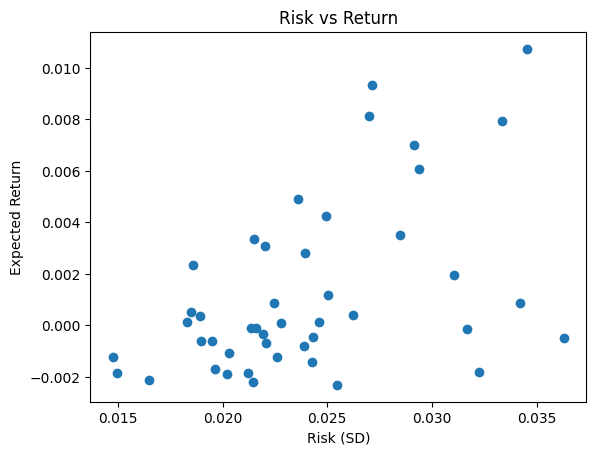

In [ ]:
import matplotlib.pyplot as plt

df = risk_results["LQ45"]["summary_plus_lstm"]

plt.scatter(df["Risk_SD"], df["Expected_Return_LSTM"])
plt.xlabel("Risk (SD)")
plt.ylabel("Expected Return")
plt.title("Risk vs Return")
plt.show()

In [ ]:
import numpy as np
import pandas as pd

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

benchmark_results = []

for idx_name, res in all_results.items():
    test_df = res["test_predictions"].copy()
    hist_mean_map = (
        risk_results[idx_name]["summary_plus_lstm"]
        .set_index("Ticker")["Mean_Return_Historical"]
        .to_dict()
    )

    for ticker, g in test_df.groupby("Ticker"):
        y_true = g["Actual"].values
        y_lstm = g["Predicted"].values
        y_zero = np.zeros_like(y_true)
        y_hist = np.full_like(y_true, hist_mean_map.get(ticker, np.nan), dtype=float)

        benchmark_results.append({
            "Index": idx_name,
            "Ticker": ticker,
            "RMSE_LSTM": rmse(y_true, y_lstm),
            "MAE_LSTM": mae(y_true, y_lstm),
            "RMSE_Zero": rmse(y_true, y_zero),
            "MAE_Zero": mae(y_true, y_zero),
            "RMSE_HistMean": rmse(y_true, y_hist),
            "MAE_HistMean": mae(y_true, y_hist)
        })

benchmark_df = pd.DataFrame(benchmark_results)

benchmark_df["RMSE_Improvement_vs_Zero_%"] = 100 * (
    benchmark_df["RMSE_Zero"] - benchmark_df["RMSE_LSTM"]
) / benchmark_df["RMSE_Zero"]

benchmark_df["MAE_Improvement_vs_Zero_%"] = 100 * (
    benchmark_df["MAE_Zero"] - benchmark_df["MAE_LSTM"]
) / benchmark_df["MAE_Zero"]

benchmark_df["RMSE_Improvement_vs_HistMean_%"] = 100 * (
    benchmark_df["RMSE_HistMean"] - benchmark_df["RMSE_LSTM"]
) / benchmark_df["RMSE_HistMean"]

benchmark_df["MAE_Improvement_vs_HistMean_%"] = 100 * (
    benchmark_df["MAE_HistMean"] - benchmark_df["MAE_LSTM"]
) / benchmark_df["MAE_HistMean"]

benchmark_summary = (
    benchmark_df.groupby("Index")[[
        "RMSE_LSTM", "MAE_LSTM",
        "RMSE_Zero", "MAE_Zero",
        "RMSE_HistMean", "MAE_HistMean",
        "RMSE_Improvement_vs_Zero_%", "MAE_Improvement_vs_Zero_%",
        "RMSE_Improvement_vs_HistMean_%", "MAE_Improvement_vs_HistMean_%"
    ]]
    .mean()
    .reset_index()
)

print(benchmark_summary)
benchmark_df.head()

   Index  RMSE_LSTM  MAE_LSTM  RMSE_Zero  MAE_Zero  RMSE_HistMean  \
0   DJIA   0.019939  0.014523   0.019915  0.014482       0.019892   
1   LQ45   0.027453  0.020098   0.027348  0.019934       0.027366   
2  SSE50   0.020356  0.015359   0.020228  0.015234       0.020213   

   MAE_HistMean  RMSE_Improvement_vs_Zero_%  MAE_Improvement_vs_Zero_%  \
0      0.014441                    0.075128                  -0.082433   
1      0.019979                        -inf                       -inf   
2      0.015202                   -0.631604                  -0.684511   

   RMSE_Improvement_vs_HistMean_%  MAE_Improvement_vs_HistMean_%  
0                       -0.129786                      -0.413564  
1                        0.751075                       0.279817  
2                       -0.662859                      -0.817312  


,Index,Ticker,RMSE_LSTM,MAE_LSTM,RMSE_Zero,MAE_Zero,RMSE_HistMean,MAE_HistMean,RMSE_Improvement_vs_Zero_%,MAE_Improvement_vs_Zero_%,RMSE_Improvement_vs_HistMean_%,MAE_Improvement_vs_HistMean_%
0,LQ45,ACES.JK,0.010333,0.007587,0.010065,0.007142,0.010057,0.007326,-2.670099,-6.231350,-2.749672,-3.563964
1,LQ45,ADRO.JK,0.026285,0.020120,0.026236,0.020143,0.026140,0.020062,-0.188404,0.114528,-0.556123,-0.286471
2,LQ45,AKRA.JK,0.025378,0.019514,0.025359,0.019380,0.025349,0.019438,-0.077330,-0.687013,-0.115527,-0.387109
3,LQ45,ANTM.JK,0.043795,0.033548,0.043884,0.033702,0.043780,0.033643,0.202895,0.454420,-0.033247,0.282316
4,LQ45,ASII.JK,0.032541,0.023353,0.032366,0.023433,0.032366,0.023433,-0.541673,0.340599,-0.540999,0.340602


In [ ]:
# =========================================
# A) BUILD GLOBAL INPUTS
# =========================================
import pandas as pd
import numpy as np

def build_global_inputs(risk_results):
    summary_list = []
    returns_list = []

    for idx_name, rr in risk_results.items():
        # summary_plus_lstm must already exist
        df = rr["summary_plus_lstm"].copy()
        df["Index"] = idx_name
        summary_list.append(df)

        # historical log returns
        ret = rr["log_returns"].copy()
        # add market prefix to avoid duplicated ticker names
        ret.columns = [f"{idx_name}__{c}" for c in ret.columns]
        returns_list.append(ret)

    global_summary = pd.concat(summary_list, ignore_index=True)

    # align dates across markets, keep union of dates
    global_returns = pd.concat(returns_list, axis=1).sort_index()

    # create matching key for covariance matrix lookup
    global_summary["GlobalTicker"] = global_summary["Index"] + "__" + global_summary["Ticker"]

    # covariance matrix from global historical returns
    global_cov = global_returns.cov()

    return {
        "summary_plus_lstm": global_summary,
        "log_returns": global_returns,
        "cov_matrix": global_cov
    }

global_risk = build_global_inputs(risk_results)

print(global_risk["summary_plus_lstm"].head())
print(global_risk["cov_matrix"].shape)

    Ticker  N_Obs  Mean_Return_Historical   Risk_SD    VaR_95   CVaR_95  \
0  BBCA.JK   1242                0.000039  0.014761 -0.022580 -0.031297   
1  INDF.JK   1242               -0.000046  0.014967 -0.023768 -0.034692   
2  ICBP.JK   1242               -0.000160  0.016495 -0.026123 -0.037556   
3  BBRI.JK   1242               -0.000002  0.018292 -0.027629 -0.040024   
4  ASII.JK   1242                0.000056  0.018507 -0.027076 -0.039438   

        MAD   Abs_VaR  Abs_CVaR  Expected_Return_LSTM Index   GlobalTicker  
0  0.010797  0.022580  0.031297             -0.001214  LQ45  LQ45__BBCA.JK  
1  0.011031  0.023768  0.034692             -0.001836  LQ45  LQ45__INDF.JK  
2  0.011806  0.026123  0.037556             -0.002122  LQ45  LQ45__ICBP.JK  
3  0.013421  0.027629  0.040024              0.000131  LQ45  LQ45__BBRI.JK  
4  0.013371  0.027076  0.039438              0.000522  LQ45  LQ45__ASII.JK  
(125, 125)


In [ ]:
# =========================================
# B) BUILD GLOBAL UNIVERSE
# =========================================
global_summary = global_risk["summary_plus_lstm"]
global_returns = global_risk["log_returns"]

# correlation proof
global_corr = global_returns.corr()

ticker_market_map = {col: col.split("__")[0] for col in global_returns.columns}

within_corr = []
cross_corr = []

cols = list(global_corr.columns)

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        t1, t2 = cols[i], cols[j]
        c = global_corr.loc[t1, t2]

        if pd.isna(c):
            continue

        if ticker_market_map[t1] == ticker_market_map[t2]:
            within_corr.append(c)
        else:
            cross_corr.append(c)

corr_proof = pd.DataFrame({
    "Group": ["Within_Market", "Cross_Market"],
    "N_Pairs": [len(within_corr), len(cross_corr)],
    "Mean_Correlation": [
        np.mean(within_corr) if len(within_corr) > 0 else np.nan,
        np.mean(cross_corr) if len(cross_corr) > 0 else np.nan
    ],
    "Median_Correlation": [
        np.median(within_corr) if len(within_corr) > 0 else np.nan,
        np.median(cross_corr) if len(cross_corr) > 0 else np.nan
    ]
})

market_return_df = pd.DataFrame({
    "LQ45": global_returns[[c for c in global_returns.columns if c.startswith("LQ45__")]].mean(axis=1),
    "DJIA": global_returns[[c for c in global_returns.columns if c.startswith("DJIA__")]].mean(axis=1),
    "SSE50": global_returns[[c for c in global_returns.columns if c.startswith("SSE50__")]].mean(axis=1),
})

market_corr = market_return_df.corr()

global_cov = global_returns.cov()

print(corr_proof)
print(market_corr)
print(global_cov.shape)

           Group  N_Pairs  Mean_Correlation  Median_Correlation
0  Within_Market     2650          0.221124            0.200386
1   Cross_Market     5100          0.020013            0.019417
           LQ45      DJIA     SSE50
LQ45   1.000000  0.092145  0.146302
DJIA   0.092145  1.000000  0.039910
SSE50  0.146302  0.039910  1.000000
(125, 125)


In [ ]:
# =========================================
# C) BUILD GLOBAL TEST RETURNS
# =========================================
def build_global_test_returns(all_results):
    test_list = []

    for idx_name, res in all_results.items():
        df = res["test_predictions"].copy()
        df["GlobalTicker"] = idx_name + "__" + df["Ticker"]
        test_list.append(df)

    global_test = pd.concat(test_list, ignore_index=True)

    # pivot to Date x GlobalTicker using actual Jan-Feb 2026 returns
    pivot_test = global_test.pivot(index="Date", columns="GlobalTicker", values="Actual").sort_index()

    # IMPORTANT:
    # different market holidays -> non-trading day return = 0
    pivot_test = pivot_test.fillna(0.0)

    return pivot_test

global_test_returns = build_global_test_returns(all_results)

print(global_test_returns.head())
print(global_test_returns.shape)

GlobalTicker  DJIA__AAPL  DJIA__AMGN  DJIA__AMZN  DJIA__AXP  DJIA__BA  \
Date                                                                    
2026-01-02     -0.003131    0.001008   -0.018893   0.007486  0.047886   
2026-01-05     -0.013934   -0.021347    0.028551   0.018790  0.001579   
2026-01-06     -0.018504    0.029039    0.033210   0.009851  0.007468   
2026-01-07     -0.007768    0.034150    0.002611  -0.014020 -0.007512   
2026-01-08     -0.004967   -0.034332    0.019392   0.012507 -0.003249   

GlobalTicker  DJIA__CAT  DJIA__CRM  DJIA__CSCO  DJIA__CVX  DJIA__DIS  ...  \
Date                                                                  ...   
2026-01-02     0.043617  -0.043553   -0.012935   0.022640  -0.017020  ...   
2026-01-05     0.029133   0.010356   -0.006068   0.049737   0.019654  ...   
2026-01-06     0.011282   0.025581   -0.004642  -0.045640   0.004374  ...   
2026-01-07    -0.043578   0.012174   -0.006802  -0.008597  -0.014595  ...   
2026-01-08     0.019276  -

In [ ]:
import numpy as np
import pandas as pd

# =========================================
# D) BACKTEST GLOBAL PORTFOLIO
# =========================================
def sortino_ratio(returns, target=0.0):
    returns = pd.Series(returns).dropna()

    if len(returns) == 0:
        return np.nan

    downside = np.minimum(returns - target, 0.0)
    downside_dev = np.sqrt(np.mean(downside ** 2))

    if downside_dev <= 1e-12:
        return np.nan

    return (returns.mean() - target) / downside_dev

def max_drawdown(cum_wealth):
    cum_wealth = pd.Series(cum_wealth).dropna()

    if len(cum_wealth) == 0:
        return np.nan

    running_max = cum_wealth.cummax()
    drawdown = (cum_wealth / running_max) - 1.0
    return drawdown.min()

def backtest_global_portfolio(global_portfolio_result, global_test_returns, weight_col="Weight_MaxSharpe"):
    weights_df = global_portfolio_result["weights"][["GlobalTicker", weight_col]].copy()
    weights_df = weights_df.rename(columns={weight_col: "Weight"})
    weights_df = weights_df[weights_df["Weight"] > 1e-8].copy()

    common_tickers = [t for t in weights_df["GlobalTicker"] if t in global_test_returns.columns]
    weights_df = weights_df[weights_df["GlobalTicker"].isin(common_tickers)].copy()
    test_mat = global_test_returns[common_tickers].copy()

    # make sure no NaN survives
    test_mat = test_mat.fillna(0.0)

    w = weights_df.set_index("GlobalTicker")["Weight"].values
    w = w / w.sum()

    port_ret = test_mat.values @ w
    port_ret = pd.Series(port_ret, index=test_mat.index, name="Portfolio_Return").dropna()

    # because returns are log returns
    cum_wealth = np.exp(port_ret.cumsum())

    realized_return_mean = port_ret.mean()
    realized_risk_sd = port_ret.std(ddof=1)
    realized_sharpe = (realized_return_mean - RF_DAILY) / realized_risk_sd if realized_risk_sd > 1e-12 else np.nan
    realized_sortino = sortino_ratio(port_ret, target=RF_DAILY)
    realized_mdd = max_drawdown(cum_wealth)

    summary = pd.DataFrame([{
        "Portfolio": "GLOBAL",
        "Weight_Type": weight_col,
        "Mean_Daily_Return": realized_return_mean,
        "Daily_Risk_SD": realized_risk_sd,
        "Sharpe": realized_sharpe,
        "Sortino": realized_sortino,
        "Final_Cumulative_Wealth": cum_wealth.iloc[-1] if len(cum_wealth) > 0 else np.nan,
        "Max_Drawdown": realized_mdd,
        "N_Test_Days": len(port_ret),
        "N_Assets_Used": len(weights_df)
    }])

    series_df = pd.DataFrame({
        "Date": port_ret.index,
        "Portfolio_Return": port_ret.values,
        "Cumulative_Wealth": cum_wealth.values
    })

    return summary, series_df, weights_df

# --- FIX STARTS HERE ---
# Build global portfolio results
global_df_optim = global_risk["summary_plus_lstm"].copy()
global_df_optim = global_df_optim.dropna(subset=["Expected_Return_LSTM", "Risk_SD"]) # Filter out any NaNs for optimization

global_tickers_optim = global_df_optim["GlobalTicker"].tolist()
global_mu_optim = global_df_optim["Expected_Return_LSTM"].values
global_cov_matrix_optim = global_risk["cov_matrix"].loc[global_tickers_optim, global_tickers_optim].values # Ensure covariance matrix aligns with filtered tickers

# Perform global optimization
w_mv_global, res_mv_global = optimize_min_variance(global_cov_matrix_optim, weight_cap=0.20)
w_ms_global, res_ms_global = optimize_max_sharpe(global_mu_optim, global_cov_matrix_optim, rf=0.0, weight_cap=0.20)

# Create a DataFrame for global weights
global_weights_df = global_df_optim[["GlobalTicker"]].copy()
global_weights_df["Weight_MinVar"] = w_mv_global
global_weights_df["Weight_MaxSharpe"] = w_ms_global

# Calculate global portfolio performance
perf_mv_global = portfolio_performance(w_mv_global, global_mu_optim, global_cov_matrix_optim, rf=0.0)
perf_ms_global = portfolio_performance(w_ms_global, global_mu_optim, global_cov_matrix_optim, rf=0.0)

# Store in global_portfolio_result
global_portfolio_result = {
    "weights": global_weights_df,
    "perf_minvar": perf_mv_global,
    "perf_maxsharpe": perf_ms_global
}

print("\n===== GLOBAL PORTFOLIO ====")
print("Min Variance:", perf_mv_global)
print("Max Sharpe  :", perf_ms_global)
# --- FIX ENDS HERE ---

global_bt_minvar, global_series_minvar, global_w_minvar = backtest_global_portfolio(
    global_portfolio_result, global_test_returns, weight_col="Weight_MinVar"
)

global_bt_maxsharpe, global_series_maxsharpe, global_w_maxsharpe = backtest_global_portfolio(
    global_portfolio_result, global_test_returns, weight_col="Weight_MaxSharpe"
)

print(global_bt_minvar)
print(global_bt_maxsharpe)


===== GLOBAL PORTFOLIO ====
Min Variance: {'Expected_Return': 0.00042369440961920185, 'Risk_SD': np.float64(0.00658878379544202), 'Sharpe': np.float64(0.06430540487795404)}
Max Sharpe  : {'Expected_Return': 0.004373646165392768, 'Risk_SD': np.float64(0.00752878249390188), 'Sharpe': np.float64(0.5809234320337066)}
  Portfolio    Weight_Type  Mean_Daily_Return  Daily_Risk_SD    Sharpe  \
0    GLOBAL  Weight_MinVar            0.00059       0.006546  0.057734   

    Sortino  Final_Cumulative_Wealth  Max_Drawdown  N_Test_Days  N_Assets_Used  
0  0.083283                  1.02389     -0.041997           40            125  
  Portfolio       Weight_Type  Mean_Daily_Return  Daily_Risk_SD    Sharpe  \
0    GLOBAL  Weight_MaxSharpe           0.004635       0.010785  0.410051   

    Sortino  Final_Cumulative_Wealth  Max_Drawdown  N_Test_Days  N_Assets_Used  
0  0.769504                 1.203687     -0.042868           40             17  


In [ ]:
import numpy as np
import pandas as pd

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

benchmark_results = []

for idx_name, res in all_results.items():
    test_df = res["test_predictions"].copy()
    hist_mean_map = (
        risk_results[idx_name]["summary_plus_lstm"]
        .set_index("Ticker")["Mean_Return_Historical"]
        .to_dict()
    )

    for ticker, g in test_df.groupby("Ticker"):
        y_true = g["Actual"].values
        y_lstm = g["Predicted"].values
        y_zero = np.zeros_like(y_true)
        y_hist = np.full_like(y_true, hist_mean_map.get(ticker, np.nan), dtype=float)

        benchmark_results.append({
            "Index": idx_name,
            "Ticker": ticker,
            "RMSE_LSTM": rmse(y_true, y_lstm),
            "MAE_LSTM": mae(y_true, y_lstm),
            "RMSE_Zero": rmse(y_true, y_zero),
            "MAE_Zero": mae(y_true, y_zero),
            "RMSE_HistMean": rmse(y_true, y_hist),
            "MAE_HistMean": mae(y_true, y_hist)
        })

benchmark_df = pd.DataFrame(benchmark_results)

benchmark_df["RMSE_Improvement_vs_Zero_%"] = 100 * (
    benchmark_df["RMSE_Zero"] - benchmark_df["RMSE_LSTM"]
) / benchmark_df["RMSE_Zero"]

benchmark_df["MAE_Improvement_vs_Zero_%"] = 100 * (
    benchmark_df["MAE_Zero"] - benchmark_df["MAE_LSTM"]
) / benchmark_df["MAE_Zero"]

benchmark_df["RMSE_Improvement_vs_HistMean_%"] = 100 * (
    benchmark_df["RMSE_HistMean"] - benchmark_df["RMSE_LSTM"]
) / benchmark_df["RMSE_HistMean"]

benchmark_df["MAE_Improvement_vs_HistMean_%"] = 100 * (
    benchmark_df["MAE_HistMean"] - benchmark_df["MAE_LSTM"]
) / benchmark_df["MAE_HistMean"]

benchmark_summary = (
    benchmark_df.groupby("Index")[[
        "RMSE_LSTM", "MAE_LSTM",
        "RMSE_Zero", "MAE_Zero",
        "RMSE_HistMean", "MAE_HistMean",
        "RMSE_Improvement_vs_Zero_%", "MAE_Improvement_vs_Zero_%",
        "RMSE_Improvement_vs_HistMean_%", "MAE_Improvement_vs_HistMean_%"
    ]]
    .mean()
    .reset_index()
)

print(benchmark_summary)
benchmark_df.head()

# =========================================
# E) COMPARISON TABLE: SINGLE-MARKET vs GLOBAL
# =========================================
comparison_rows = []

single_market_backtest_rows = []

for idx_name, res in portfolio_results.items():
    weights_df_single = res["weights"].copy()
    weights_df_single["GlobalTicker"] = idx_name + "__" + weights_df_single["Ticker"]

    # Backtest MinVar portfolio for this single market
    temp_minvar_portfolio_result = {"weights": weights_df_single}
    bt_mv_single, _, _ = backtest_global_portfolio(
        temp_minvar_portfolio_result,
        global_test_returns,
        weight_col="Weight_MinVar"
    )
    bt_mv_single["Portfolio"] = idx_name
    single_market_backtest_rows.append(bt_mv_single)

    # Backtest MaxSharpe portfolio for this single market
    temp_maxsharpe_portfolio_result = {"weights": weights_df_single}
    bt_ms_single, _, _ = backtest_global_portfolio(
        temp_maxsharpe_portfolio_result,
        global_test_returns,
        weight_col="Weight_MaxSharpe"
    )
    bt_ms_single["Portfolio"] = idx_name
    single_market_backtest_rows.append(bt_ms_single)

single_market_comp = pd.concat(single_market_backtest_rows, ignore_index=True)

comparison_rows.append(single_market_comp)

global_comp = pd.concat([global_bt_minvar, global_bt_maxsharpe], ignore_index=True)
comparison_rows.append(global_comp)

comparison_table = pd.concat(comparison_rows, ignore_index=True)

# keep clean columns
comparison_table = comparison_table[[
    "Portfolio", "Weight_Type",
    "Mean_Daily_Return", "Daily_Risk_SD", "Sharpe", "Sortino",
    "Final_Cumulative_Wealth", "Max_Drawdown",
    "N_Test_Days", "N_Assets_Used"
]]

comparison_table = comparison_table.sort_values(
    ["Weight_Type", "Sortino", "Sharpe"],
    ascending=[True, False, False]
)

print(comparison_table)
comparison_table

# =========================================
# BASELINE PORTFOLIOS
# Equal-Weight (EW) and Buy-and-Hold (BH)
# Added after comparison table — Cell 25
# =========================================

def backtest_equal_weight(index_name, all_results, rf=RF_DAILY):
    """1/N portfolio, rebalanced daily."""
    test_df = all_results[index_name]["test_predictions"].copy()
    pivot = (
        test_df.pivot(index="Date", columns="Ticker", values="Actual")
        .sort_index().fillna(0.0)
    )
    n  = pivot.shape[1]
    w  = np.ones(n) / n
    r  = pd.Series(pivot.values @ w, index=pivot.index)
    cw = np.exp(r.cumsum())
    sd = r.std(ddof=1)
    return pd.DataFrame([{
        "Portfolio": index_name, "Weight_Type": "Equal_Weight",
        "Mean_Daily_Return": r.mean(),
        "Daily_Risk_SD":     sd,
        "Sharpe":  (r.mean() - rf) / sd if sd > 1e-12 else np.nan,
        "Sortino": sortino_ratio(r, target=rf),
        "Final_Cumulative_Wealth": cw.iloc[-1],
        "Max_Drawdown": max_drawdown(cw),
        "N_Test_Days": len(r), "N_Assets_Used": n
    }])


def backtest_buy_and_hold(index_name, all_results, rf=RF_DAILY):
    """Equal weights at start, NO daily rebalancing."""
    test_df = all_results[index_name]["test_predictions"].copy()
    pivot = (
        test_df.pivot(index="Date", columns="Ticker", values="Actual")
        .sort_index().fillna(0.0)
    )
    n   = pivot.shape[1]
    w0  = np.ones(n) / n
    ret = pivot.values                            # (T, N)
    # cumulative asset values from t=0
    asset_cw   = np.exp(np.cumsum(ret, axis=0))  # (T, N)
    port_value = asset_cw @ w0                   # (T,)
    r_vals     = np.concatenate([[0.0], np.diff(np.log(port_value))])
    r  = pd.Series(r_vals, index=pivot.index)
    cw = pd.Series(np.exp(np.cumsum(r_vals)), index=pivot.index)
    sd = r.std(ddof=1)
    return pd.DataFrame([{
        "Portfolio": index_name, "Weight_Type": "Buy_and_Hold",
        "Mean_Daily_Return": r.mean(),
        "Daily_Risk_SD":     sd,
        "Sharpe":  (r.mean() - rf) / sd if sd > 1e-12 else np.nan,
        "Sortino": sortino_ratio(r, target=rf),
        "Final_Cumulative_Wealth": cw.iloc[-1],
        "Max_Drawdown": max_drawdown(cw),
        "N_Test_Days": len(r), "N_Assets_Used": n
    }])


def backtest_equal_weight_global(global_test_returns, rf=RF_DAILY):
    """1/N across all global assets."""
    n  = global_test_returns.shape[1]
    w  = np.ones(n) / n
    r  = pd.Series(
        global_test_returns.fillna(0.0).values @ w,
        index=global_test_returns.index
    )
    cw = np.exp(r.cumsum())
    sd = r.std(ddof=1)
    return pd.DataFrame([{
        "Portfolio": "GLOBAL", "Weight_Type": "Equal_Weight",
        "Mean_Daily_Return": r.mean(),
        "Daily_Risk_SD":     sd,
        "Sharpe":  (r.mean() - rf) / sd if sd > 1e-12 else np.nan,
        "Sortino": sortino_ratio(r, target=rf),
        "Final_Cumulative_Wealth": cw.iloc[-1],
        "Max_Drawdown": max_drawdown(cw),
        "N_Test_Days": len(r), "N_Assets_Used": n
    }])


# ─── Run all baselines ───
baseline_rows = []
for idx_name in ["LQ45", "DJIA", "SSE50"]:
    baseline_rows.append(backtest_equal_weight(idx_name, all_results))
    baseline_rows.append(backtest_buy_and_hold(idx_name, all_results))

baseline_rows.append(backtest_equal_weight_global(global_test_returns))

baseline_df = pd.concat(baseline_rows, ignore_index=True)

print("\n===== BASELINE PORTFOLIOS (Equal-Weight & Buy-and-Hold) =====")
print(baseline_df.to_string(index=False))
# =========================================
# SLIDING WINDOW ROBUSTNESS CHECK
# Window = 10 trading days, step = 5 days
# ~6 windows over the 39-day test period
# =========================================

def sliding_window_robustness(
    port_returns_dict,
    window_size=10,
    step=5,
    rf=RF_DAILY
):
    """
    port_returns_dict: {label: pd.Series of daily log returns}
    Returns a long DataFrame: one row per (window, portfolio).
    """
    all_s  = pd.DataFrame(port_returns_dict).sort_index().dropna(how="all")
    dates  = all_s.index
    T      = len(dates)
    results = []
    start, win_id = 0, 1

    while start + window_size <= T:
        end   = start + window_size
        wdates = dates[start:end]
        label  = (f"W{win_id} "
                  f"({wdates[0].strftime('%m/%d')}–"
                  f"{wdates[-1].strftime('%m/%d')})")
        for col in all_s.columns:
            r  = all_s.loc[wdates, col].dropna()
            if len(r) < 3:
                continue
            sd = r.std(ddof=1)
            results.append({
                "Window":    label,
                "Win_Start": wdates[0],
                "Portfolio": col,
                "Sharpe":    (r.mean() - rf) / sd if sd > 1e-12 else np.nan,
                "Sortino":   sortino_ratio(r, target=rf),
                "Cum_Wealth":float(np.exp(r.sum())),
                "Mean_Ret":  r.mean()
            })
        start  += step
        win_id += 1

    return pd.DataFrame(results)


# ─── Build MaxSharpe daily return series ───
# NOTE: replace variable names if your backtest output is named differently
port_series_ms = {}

for idx_name in ["LQ45", "DJIA", "SSE50"]:
    # pull the 'Actual' column from test_predictions as realized daily return
    tp = all_results[idx_name]["test_predictions"].copy()
    pivot_tp = (
        tp.pivot(index="Date", columns="Ticker", values="Actual")
        .sort_index().fillna(0.0)
    )
    # weights from the MaxSharpe optimization
    wdf = portfolio_results[idx_name]["weights"].copy()
    wdf = wdf[wdf["Weight_MaxSharpe"] > 1e-8]
    common = [t for t in wdf["Ticker"] if t in pivot_tp.columns]
    w = wdf.set_index("Ticker").loc[common, "Weight_MaxSharpe"].values
    w = w / w.sum()
    r = pd.Series(pivot_tp[common].values @ w, index=pivot_tp.index)
    port_series_ms[f"{idx_name}_MaxSharpe"] = r

# Global MaxSharpe — use your existing global_ms_series_df
# Variable name: check what your Cell 25 calls the output series
# If it is called global_ms_series_df, run:
try:
    port_series_ms["GLOBAL_MaxSharpe"] = pd.Series(
        global_series_maxsharpe["Portfolio_Return"].values,
        index=pd.to_datetime(global_series_maxsharpe["Date"].values)
    )
except Exception as e:
    print(f"Could not load global series: {e}")
    print("Run the global backtest cell first, then re-run this cell.")


# ─── Run robustness check ───
robustness_df = sliding_window_robustness(
    port_series_ms, window_size=10, step=5
)

# Sharpe pivot table
rob_sharpe = robustness_df.pivot(
    index="Window", columns="Portfolio", values="Sharpe"
)
rob_sharpe.columns.name = None

# Rank per window (1 = best Sharpe in that window)
rob_rank = rob_sharpe.rank(axis=1, ascending=False)

print("\n===== SLIDING WINDOW: Sharpe per sub-period =====")
print(rob_sharpe.round(4).to_string())

print("\n===== RANK PER WINDOW (1 = best) =====")
print(rob_rank.to_string())

print("\n===== MEAN RANK across all windows =====")
print(rob_rank.mean().sort_values().round(2).to_string(index=False))

   Index  RMSE_LSTM  MAE_LSTM  RMSE_Zero  MAE_Zero  RMSE_HistMean  \
0   DJIA   0.019939  0.014523   0.019915  0.014482       0.019892   
1   LQ45   0.027453  0.020098   0.027348  0.019934       0.027366   
2  SSE50   0.020356  0.015359   0.020228  0.015234       0.020213   

   MAE_HistMean  RMSE_Improvement_vs_Zero_%  MAE_Improvement_vs_Zero_%  \
0      0.014441                    0.075128                  -0.082433   
1      0.019979                        -inf                       -inf   
2      0.015202                   -0.631604                  -0.684511   

   RMSE_Improvement_vs_HistMean_%  MAE_Improvement_vs_HistMean_%  
0                       -0.129786                      -0.413564  
1                        0.751075                       0.279817  
2                       -0.662859                      -0.817312  
  Portfolio       Weight_Type  Mean_Daily_Return  Daily_Risk_SD    Sharpe  \
3      DJIA  Weight_MaxSharpe           0.003980       0.008544  0.440932   
7   

In [ ]:
# =========================================
# STATISTICAL DIFFERENCE TESTS
# Kruskal-Wallis + pairwise Mann-Whitney U
# with Bonferroni correction
# =========================================
from scipy.stats import kruskal, mannwhitneyu
from itertools import combinations
import pandas as pd
import numpy as np

# --- pilih portfolio yang memang mau diuji ---
target_labels = [
    "LQ45_MaxSharpe",
    "DJIA_MaxSharpe",
    "SSE50_MaxSharpe",
    "GLOBAL_MaxSharpe"
]

# --- ambil hanya yang benar-benar ada di port_series_ms ---
available_labels = [lbl for lbl in target_labels if lbl in port_series_ms]
missing_labels = [lbl for lbl in target_labels if lbl not in port_series_ms]

print("Available portfolios for test:", available_labels)
if missing_labels:
    print("Missing portfolios (not tested):", missing_labels)

if len(available_labels) < 2:
    raise ValueError("Portfolio yang tersedia kurang dari 2, tidak bisa uji beda.")

# --- collect return arrays ---
groups = {lbl: port_series_ms[lbl].dropna().values for lbl in available_labels}

# optional check
for lbl, arr in groups.items():
    print(f"{lbl}: n = {len(arr)}")

# --- Kruskal-Wallis overall test ---
if len(groups) >= 3:
    stat_kw, p_kw = kruskal(*[groups[lbl] for lbl in available_labels])
    print("=" * 60)
    print(f"Kruskal-Wallis H = {stat_kw:.4f},  p = {p_kw:.4f}")
    if p_kw < 0.05:
        print("→ At least one distribution is significantly different (p < 0.05)")
    else:
        print("→ No significant overall difference detected (p ≥ 0.05)")
    print("=" * 60)
else:
    print("=" * 60)
    print("Kruskal-Wallis skipped: need at least 3 groups.")
    print("=" * 60)

# --- Pairwise Mann-Whitney U using explicit label combinations ---
pairs = list(combinations(available_labels, 2))
alpha_bonf = 0.05 / len(pairs)

print(f"\nPairwise Mann-Whitney U (Bonferroni α = {alpha_bonf:.4f})")
print("-" * 75)
print(f"{'Portfolio A':<25} {'Portfolio B':<25} {'U-stat':>10} {'p-value':>10} {'Sig?':>8}")
print("-" * 75)

pairwise_rows = []
for a, b in pairs:
    u, p = mannwhitneyu(groups[a], groups[b], alternative="two-sided")
    sig = "YES" if p < alpha_bonf else "no"

    print(f"{a:<25} {b:<25} {u:>10.2f} {p:>10.4f} {sig:>8}")

    pairwise_rows.append({
        "Portfolio_A": a,
        "Portfolio_B": b,
        "U_Statistic": u,
        "p_value": p,
        "Bonferroni_alpha": alpha_bonf,
        "Significant_Bonferroni": p < alpha_bonf
    })

pairwise_df = pd.DataFrame(pairwise_rows)

print("\n[NOTE] With only ~40 observations, statistical power is LOW.")
print("Non-significant ≠ portfolios are equivalent.")

Available portfolios for test: ['LQ45_MaxSharpe', 'DJIA_MaxSharpe', 'SSE50_MaxSharpe', 'GLOBAL_MaxSharpe']
LQ45_MaxSharpe: n = 38
DJIA_MaxSharpe: n = 39
SSE50_MaxSharpe: n = 34
GLOBAL_MaxSharpe: n = 40
Kruskal-Wallis H = 2.3441,  p = 0.5041
→ No significant overall difference detected (p ≥ 0.05)

Pairwise Mann-Whitney U (Bonferroni α = 0.0083)
---------------------------------------------------------------------------
Portfolio A               Portfolio B                   U-stat    p-value     Sig?
---------------------------------------------------------------------------
LQ45_MaxSharpe            DJIA_MaxSharpe                874.00     0.1770       no
LQ45_MaxSharpe            SSE50_MaxSharpe               721.00     0.4007       no
LQ45_MaxSharpe            GLOBAL_MaxSharpe              877.00     0.2442       no
DJIA_MaxSharpe            SSE50_MaxSharpe               611.00     0.5690       no
DJIA_MaxSharpe            GLOBAL_MaxSharpe              719.00     0.5530       no
SSE5

In [ ]:
# =========================================
# STATISTICAL DIFFERENCE TESTS - TRAINING PERIOD
# Kruskal-Wallis + pairwise Mann-Whitney U
# with Bonferroni correction
# =========================================
from scipy.stats import kruskal, mannwhitneyu
from itertools import combinations
import pandas as pd
import numpy as np

# -----------------------------------------
# 1) BUILD TRAINING-PERIOD MAXSHARPE SERIES
# -----------------------------------------
port_series_ms_train = {}

# --- Single-market portfolios ---
for idx_name in ["LQ45", "DJIA", "SSE50"]:
    # realized training-period returns
    ret_df = all_results[idx_name]["log_returns"].copy()
    ret_df.index = pd.to_datetime(ret_df.index)
    ret_train = ret_df[ret_df.index <= pd.to_datetime(TRAIN_END)].copy()

    # max-sharpe weights
    wdf = portfolio_results[idx_name]["weights"].copy()
    wdf = wdf[wdf["Weight_MaxSharpe"] > 1e-8].copy()

    common = [t for t in wdf["Ticker"] if t in ret_train.columns]
    if len(common) == 0:
        print(f"[WARN] No common tickers for {idx_name}_MaxSharpe in training period.")
        continue

    w = wdf.set_index("Ticker").loc[common, "Weight_MaxSharpe"].values
    w = w / w.sum()

    series = pd.Series(
        ret_train[common].fillna(0.0).values @ w,
        index=ret_train.index,
        name=f"{idx_name}_MaxSharpe"
    )

    port_series_ms_train[f"{idx_name}_MaxSharpe"] = series

# --- Global portfolio ---
# Build combined training-period returns with GlobalTicker format: INDEX__TICKER
global_train_parts = []

for idx_name in ["LQ45", "DJIA", "SSE50"]:
    ret_df = all_results[idx_name]["log_returns"].copy()
    ret_df.index = pd.to_datetime(ret_df.index)
    ret_train = ret_df[ret_df.index <= pd.to_datetime(TRAIN_END)].copy()

    ret_train_prefixed = ret_train.copy()
    ret_train_prefixed.columns = [f"{idx_name}__{c}" for c in ret_train.columns]
    global_train_parts.append(ret_train_prefixed)

global_train_returns = pd.concat(global_train_parts, axis=1).sort_index().fillna(0.0)

if "global_portfolio_result" in globals():
    gw = global_portfolio_result["weights"].copy()
    gw = gw[gw["Weight_MaxSharpe"] > 1e-8].copy()

    common_global = [g for g in gw["GlobalTicker"] if g in global_train_returns.columns]

    if len(common_global) > 0:
        wg = gw.set_index("GlobalTicker").loc[common_global, "Weight_MaxSharpe"].values
        wg = wg / wg.sum()

        global_train_series = pd.Series(
            global_train_returns[common_global].values @ wg,
            index=global_train_returns.index,
            name="GLOBAL_MaxSharpe"
        )

        port_series_ms_train["GLOBAL_MaxSharpe"] = global_train_series
    else:
        print("[WARN] No common tickers found for GLOBAL_MaxSharpe in training period.")
else:
    print("[WARN] global_portfolio_result not found. GLOBAL_MaxSharpe not included.")

# -----------------------------------------
# 2) SELECT TARGET PORTFOLIOS
# -----------------------------------------
target_labels = [
    "LQ45_MaxSharpe",
    "DJIA_MaxSharpe",
    "SSE50_MaxSharpe",
    "GLOBAL_MaxSharpe"
]

available_labels = [lbl for lbl in target_labels if lbl in port_series_ms_train]
missing_labels = [lbl for lbl in target_labels if lbl not in port_series_ms_train]

print("Available portfolios for TRAINING-period test:", available_labels)
if missing_labels:
    print("Missing portfolios (not tested):", missing_labels)

if len(available_labels) < 2:
    raise ValueError("Portfolio training-period series yang tersedia kurang dari 2, tidak bisa uji beda.")

groups = {lbl: port_series_ms_train[lbl].dropna().values for lbl in available_labels}

for lbl, arr in groups.items():
    print(f"{lbl}: n = {len(arr)}")

# -----------------------------------------
# 3) KRUSKAL-WALLIS OVERALL TEST
# -----------------------------------------
if len(groups) >= 3:
    stat_kw, p_kw = kruskal(*[groups[lbl] for lbl in available_labels])
    print("=" * 60)
    print("TRAINING PERIOD")
    print(f"Kruskal-Wallis H = {stat_kw:.4f},  p = {p_kw:.4f}")
    if p_kw < 0.05:
        print("→ At least one distribution is significantly different (p < 0.05)")
    else:
        print("→ No significant overall difference detected (p ≥ 0.05)")
    print("=" * 60)
else:
    print("=" * 60)
    print("Kruskal-Wallis skipped: need at least 3 groups.")
    print("=" * 60)

# -----------------------------------------
# 4) PAIRWISE MANN-WHITNEY U
# -----------------------------------------
pairs = list(combinations(available_labels, 2))
alpha_bonf = 0.05 / len(pairs)

print(f"\nPairwise Mann-Whitney U - TRAINING PERIOD (Bonferroni α = {alpha_bonf:.4f})")
print("-" * 80)
print(f"{'Portfolio A':<25} {'Portfolio B':<25} {'U-stat':>10} {'p-value':>10} {'Sig?':>8}")
print("-" * 80)

pairwise_rows_train = []
for a, b in pairs:
    u, p = mannwhitneyu(groups[a], groups[b], alternative="two-sided")
    sig = "YES" if p < alpha_bonf else "no"

    print(f"{a:<25} {b:<25} {u:>10.2f} {p:>10.4f} {sig:>8}")

    pairwise_rows_train.append({
        "Portfolio_A": a,
        "Portfolio_B": b,
        "U_Statistic": u,
        "p_value": p,
        "Bonferroni_alpha": alpha_bonf,
        "Significant_Bonferroni": p < alpha_bonf
    })

pairwise_train_df = pd.DataFrame(pairwise_rows_train)

print("\n[NOTE] This is an IN-SAMPLE (training-period) comparison.")
print("Use it only as supplementary evidence, not as the main result.")

Available portfolios for TRAINING-period test: ['LQ45_MaxSharpe', 'DJIA_MaxSharpe', 'SSE50_MaxSharpe', 'GLOBAL_MaxSharpe']
LQ45_MaxSharpe: n = 1204
DJIA_MaxSharpe: n = 1254
SSE50_MaxSharpe: n = 1211
GLOBAL_MaxSharpe: n = 1300
TRAINING PERIOD
Kruskal-Wallis H = 7.6589,  p = 0.0536
→ No significant overall difference detected (p ≥ 0.05)

Pairwise Mann-Whitney U - TRAINING PERIOD (Bonferroni α = 0.0083)
--------------------------------------------------------------------------------
Portfolio A               Portfolio B                   U-stat    p-value     Sig?
--------------------------------------------------------------------------------
LQ45_MaxSharpe            DJIA_MaxSharpe             712423.00     0.0157       no
LQ45_MaxSharpe            SSE50_MaxSharpe            694427.00     0.0435       no
LQ45_MaxSharpe            GLOBAL_MaxSharpe           745917.00     0.0424       no
DJIA_MaxSharpe            SSE50_MaxSharpe            760838.00     0.9305       no
DJIA_MaxSharpe     

In [ ]:
#ASSET MANA AJA YANG DIPAKE
def extract_used_assets(weights_df, weight_col, portfolio_name, threshold=1e-8):
    temp = weights_df.copy()
    temp = temp[temp[weight_col].abs() > threshold].copy()
    temp = temp.sort_values(by=weight_col, ascending=False).reset_index(drop=True)

    cols_to_keep = [c for c in ["Index", "Ticker", "GlobalTicker", "Expected_Return_LSTM", "Risk_SD", weight_col] if c in temp.columns]
    temp = temp[cols_to_keep]

    temp["Portfolio"] = portfolio_name
    temp["Weight_Type"] = weight_col

    return temp

used_assets_single = []

for idx_name, res in portfolio_results.items():
    wdf = res["weights"].copy()

    if "Index" not in wdf.columns:
        wdf["Index"] = idx_name

    used_assets_single.append(
        extract_used_assets(wdf, "Weight_MinVar", idx_name, threshold=1e-8)
    )
    used_assets_single.append(
        extract_used_assets(wdf, "Weight_MaxSharpe", idx_name, threshold=1e-8)
    )

used_assets_single_df = pd.concat(used_assets_single, ignore_index=True)

print(used_assets_single_df)

used_assets_global = []

gdf = global_portfolio_result["weights"].copy()

used_assets_global.append(
    extract_used_assets(gdf, "Weight_MinVar", "GLOBAL", threshold=1e-8)
)
used_assets_global.append(
    extract_used_assets(gdf, "Weight_MaxSharpe", "GLOBAL", threshold=1e-8)
)

used_assets_global_df = pd.concat(used_assets_global, ignore_index=True)

print(used_assets_global_df)

     Index     Ticker  Expected_Return_LSTM   Risk_SD  Weight_MinVar  \
0     LQ45    BBCA.JK             -0.001214  0.014761       0.022222   
1     LQ45    INDF.JK             -0.001836  0.014967       0.022222   
2     LQ45    ICBP.JK             -0.002122  0.016495       0.022222   
3     LQ45    BBRI.JK              0.000131  0.018292       0.022222   
4     LQ45    ASII.JK              0.000522  0.018507       0.022222   
..     ...        ...                   ...       ...            ...   
143  SSE50  601390.SS              0.003105  0.019634            NaN   
144  SSE50  600111.SS              0.005644  0.030463            NaN   
145  SSE50  601899.SS              0.004293  0.024384            NaN   
146  SSE50  601857.SS              0.002541  0.018925            NaN   
147  SSE50  600309.SS              0.002813  0.020572            NaN   

    Portfolio       Weight_Type  Weight_MaxSharpe  
0        LQ45     Weight_MinVar               NaN  
1        LQ45     Weight_MinVar

In [ ]:
# =========================================
# SUMMARY BOBOT PER MARKET - GLOBAL PORTFOLIO
# =========================================
def summarize_market_weights(global_weights_df, weight_col="Weight_MaxSharpe", threshold=1e-8):
    temp = global_weights_df.copy()

    if "Index" not in temp.columns:
        if "GlobalTicker" in temp.columns:
            temp["Index"] = temp["GlobalTicker"].str.split("__").str[0]
        else:
            raise ValueError("Need either 'Index' or 'GlobalTicker' column in global weights dataframe.")

    temp = temp[temp[weight_col].abs() > threshold].copy()

    summary = (
        temp.groupby("Index", as_index=False)
            .agg(
                N_Assets_Used=(weight_col, "count"),
                Total_Weight=(weight_col, "sum"),
                Avg_Weight=(weight_col, "mean"),
                Max_Weight=(weight_col, "max")
            )
            .sort_values("Total_Weight", ascending=False)
            .reset_index(drop=True)
    )

    if summary["Total_Weight"].sum() > 0:
        summary["Weight_Share_Pct"] = 100 * summary["Total_Weight"] / summary["Total_Weight"].sum()
    else:
        summary["Weight_Share_Pct"] = np.nan

    return summary

In [ ]:
# GLOBAL MAX SHARPE - SUMMARY BOBOT PER MARKET
global_market_weight_maxsharpe = summarize_market_weights(
    global_portfolio_result["weights"],
    weight_col="Weight_MaxSharpe",
    threshold=1e-8
)

print("=== GLOBAL MAX SHARPE: MARKET WEIGHT SUMMARY ===")
print(global_market_weight_maxsharpe)
global_market_weight_maxsharpe

=== GLOBAL MAX SHARPE: MARKET WEIGHT SUMMARY ===
   Index  N_Assets_Used  Total_Weight  Avg_Weight  Max_Weight  \
0   DJIA              6      0.427393    0.071232    0.141364   
1   LQ45              6      0.329242    0.054874    0.101725   
2  SSE50              5      0.243365    0.048673    0.079928   

   Weight_Share_Pct  
0         42.739349  
1         32.924175  
2         24.336476  


,Index,N_Assets_Used,Total_Weight,Avg_Weight,Max_Weight,Weight_Share_Pct
0,DJIA,6,0.427393,0.071232,0.141364,42.739349
1,LQ45,6,0.329242,0.054874,0.101725,32.924175
2,SSE50,5,0.243365,0.048673,0.079928,24.336476


In [ ]:
# GLOBAL MIN VAR - SUMMARY BOBOT PER MARKET
global_market_weight_minvar = summarize_market_weights(
    global_portfolio_result["weights"],
    weight_col="Weight_MinVar",
    threshold=1e-8
)

print("=== GLOBAL MIN VAR: MARKET WEIGHT SUMMARY ===")
print(global_market_weight_minvar)
global_market_weight_minvar

=== GLOBAL MIN VAR: MARKET WEIGHT SUMMARY ===
   Index  N_Assets_Used  Total_Weight  Avg_Weight  Max_Weight  \
0  SSE50             50          0.40       0.008       0.008   
1   LQ45             45          0.36       0.008       0.008   
2   DJIA             30          0.24       0.008       0.008   

   Weight_Share_Pct  
0              40.0  
1              36.0  
2              24.0  


,Index,N_Assets_Used,Total_Weight,Avg_Weight,Max_Weight,Weight_Share_Pct
0,SSE50,50,0.40,0.008,0.008,40.0
1,LQ45,45,0.36,0.008,0.008,36.0
2,DJIA,30,0.24,0.008,0.008,24.0


In [ ]:
# =========================================
# TOP ASSETS PER MARKET - GLOBAL MAX SHARPE
# =========================================
def top_assets_by_market(global_weights_df, weight_col="Weight_MaxSharpe", top_n=5, threshold=1e-8):
    temp = global_weights_df.copy()

    if "Index" not in temp.columns:
        if "GlobalTicker" in temp.columns:
            temp["Index"] = temp["GlobalTicker"].str.split("__").str[0]
        else:
            raise ValueError("Need either 'Index' or 'GlobalTicker' column in global weights dataframe.")

    temp = temp[temp[weight_col].abs() > threshold].copy()

    cols = [c for c in ["Index", "Ticker", "GlobalTicker", "Expected_Return_LSTM", "Risk_SD", weight_col] if c in temp.columns]
    temp = temp[cols].copy()

    temp = temp.sort_values(["Index", weight_col], ascending=[True, False])
    temp = temp.groupby("Index", group_keys=False).head(top_n).reset_index(drop=True)
    temp = temp.rename(columns={weight_col: "Weight"})

    return temp

In [ ]:
# =========================================
# TOP ASSETS PER MARKET - GLOBAL MAX SHARPE
# =========================================
def top_assets_by_market(global_weights_df, weight_col="Weight_MaxSharpe", top_n=5, threshold=1e-8):
    temp = global_weights_df.copy()

    if "Index" not in temp.columns:
        if "GlobalTicker" in temp.columns:
            temp["Index"] = temp["GlobalTicker"].str.split("__").str[0]
        else:
            raise ValueError("Need either 'Index' or 'GlobalTicker' column in global weights dataframe.")

    temp = temp[temp[weight_col].abs() > threshold].copy()

    cols = [c for c in ["Index", "Ticker", "GlobalTicker", "Expected_Return_LSTM", "Risk_SD", weight_col] if c in temp.columns]
    temp = temp[cols].copy()

    temp = temp.sort_values(["Index", weight_col], ascending=[True, False])
    temp = temp.groupby("Index", group_keys=False).head(top_n).reset_index(drop=True)
    temp = temp.rename(columns={weight_col: "Weight"})

    return temp

In [ ]:
# TOP 5 ASET PER MARKET DI GLOBAL MAX SHARPE
global_top_assets_by_market = top_assets_by_market(
    global_portfolio_result["weights"],
    weight_col="Weight_MaxSharpe",
    top_n=5,
    threshold=1e-8
)

print("=== TOP ASSETS BY MARKET: GLOBAL MAX SHARPE ===")
print(global_top_assets_by_market)
global_top_assets_by_market

=== TOP ASSETS BY MARKET: GLOBAL MAX SHARPE ===
    Index      GlobalTicker    Weight
0    DJIA         DJIA__JNJ  0.141364
1    DJIA         DJIA__TRV  0.106042
2    DJIA         DJIA__MRK  0.087566
3    DJIA          DJIA__VZ  0.064638
4    DJIA         DJIA__CAT  0.020722
5    LQ45     LQ45__INKP.JK  0.101725
6    LQ45     LQ45__TINS.JK  0.059240
7    LQ45     LQ45__GGRM.JK  0.056515
8    LQ45     LQ45__UNVR.JK  0.047650
9    LQ45     LQ45__MDKA.JK  0.032961
10  SSE50  SSE50__600893.SS  0.079928
11  SSE50  SSE50__601390.SS  0.046711
12  SSE50  SSE50__601288.SS  0.043803
13  SSE50  SSE50__600111.SS  0.038402
14  SSE50  SSE50__601857.SS  0.034521


,Index,GlobalTicker,Weight
0,DJIA,DJIA__JNJ,0.141364
1,DJIA,DJIA__TRV,0.106042
2,DJIA,DJIA__MRK,0.087566
3,DJIA,DJIA__VZ,0.064638
4,DJIA,DJIA__CAT,0.020722
5,LQ45,LQ45__INKP.JK,0.101725
6,LQ45,LQ45__TINS.JK,0.059240
7,LQ45,LQ45__GGRM.JK,0.056515
8,LQ45,LQ45__UNVR.JK,0.047650
9,LQ45,LQ45__MDKA.JK,0.032961


In [ ]:
# =========================================
# RINGKASAN FINAL UNTUK GLOBAL MAX SHARPE
# =========================================
global_used_maxsharpe = extract_used_assets(
    global_portfolio_result["weights"],
    "Weight_MaxSharpe",
    portfolio_name="GLOBAL",
    threshold=1e-8
)

global_market_weight_maxsharpe = summarize_market_weights(
    global_portfolio_result["weights"],
    weight_col="Weight_MaxSharpe",
    threshold=1e-8
)

global_top_assets_by_market = top_assets_by_market(
    global_portfolio_result["weights"],
    weight_col="Weight_MaxSharpe",
    top_n=5,
    threshold=1e-8
)

In [ ]:
# OPTIONAL EXPORT
with pd.ExcelWriter("global_portfolio_structure.xlsx") as writer:
    global_used_maxsharpe.to_excel(writer, sheet_name="Used_Assets_MaxSharpe", index=False)
    global_market_weight_maxsharpe.to_excel(writer, sheet_name="Market_Weights_MaxSharpe", index=False)
    global_top_assets_by_market.to_excel(writer, sheet_name="Top_Assets_By_Market", index=False)

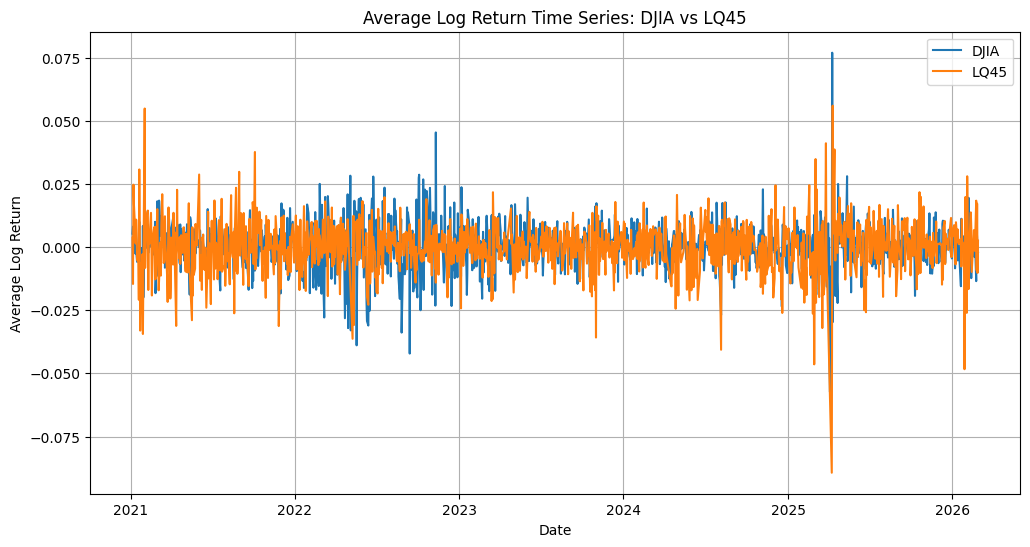

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# ambil log return dari hasil yang sudah kamu simpan
djia_returns = all_results["DJIA"]["log_returns"].copy()
lq45_returns = all_results["LQ45"]["log_returns"].copy()

# rata-rata return harian per market
djia_avg_return = djia_returns.mean(axis=1)
lq45_avg_return = lq45_returns.mean(axis=1)

plt.figure(figsize=(12, 6))
plt.plot(djia_avg_return.index, djia_avg_return, label="DJIA")
plt.plot(lq45_avg_return.index, lq45_avg_return, label="LQ45")

plt.title("Average Log Return Time Series: DJIA vs LQ45")
plt.xlabel("Date")
plt.ylabel("Average Log Return")
plt.legend()
plt.grid(True)
plt.show()